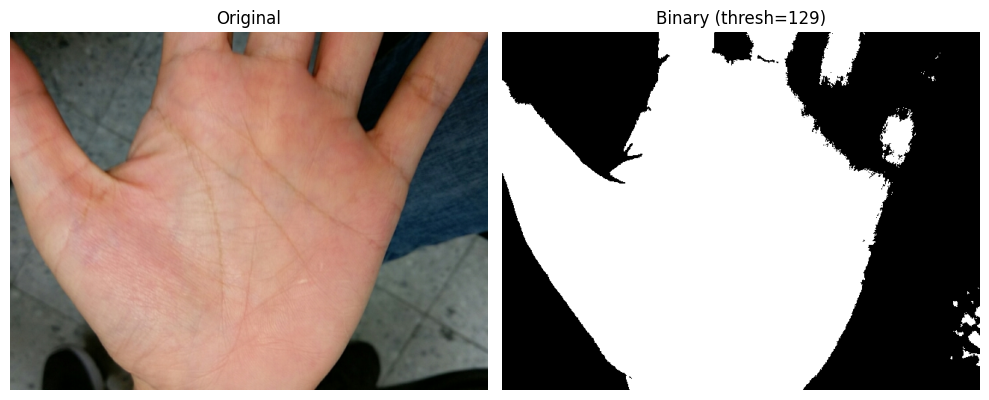

In [11]:
import cv2
from matplotlib import pyplot as plt

img = cv2.imread('../Images/200_samples/ntust-hp/0003/02.png')

# 先转换为灰度图 
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 阈值二值化
ret, img_binary = cv2.threshold(
    img_gray, 
    thresh=129,
    maxval=255, 
    type=cv2.THRESH_BINARY# + cv2.THRESH_OTSU
)

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))
# 1行2列并排显示：先创建画布和两个子图，再分别 imshow
plt.subplot(1, 2, 1)

plt.imshow(img_rgb)
plt.title('Original')
plt.axis('off')

# 灰度/二值图是单通道，用 cmap='gray' 显示即可，不要转 RGB
plt.subplot(1, 2, 2)
plt.imshow(img_binary, cmap='gray')
plt.title(f'Binary (thresh={ret:.0f})')
plt.axis('off')

plt.tight_layout()
plt.show()


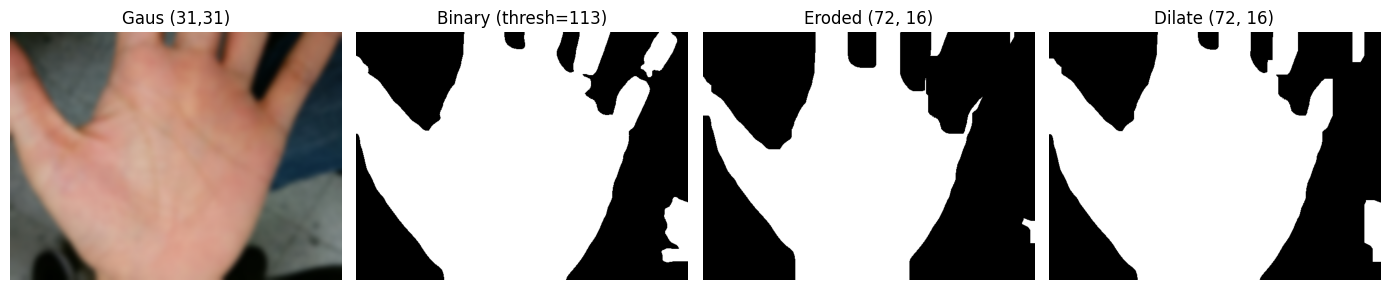

In [8]:
plt.figure(figsize=(14, 14))
plt.subplot(1, 4, 1)
img_gaus = cv2.GaussianBlur(img, (31, 31), 0)
img_gaus_rgb = cv2.cvtColor(img_gaus, cv2.COLOR_BGR2RGB)
plt.title("Gaus (31,31)")
plt.imshow(img_gaus_rgb)
plt.axis('off')

plt.subplot(1, 4, 2)
img_gaus_gray = cv2.cvtColor(img_gaus, cv2.COLOR_BGR2GRAY)
ret, img_gaus_gray_binary = cv2.threshold(
    img_gaus_gray, 
    thresh=120,
    maxval=255, 
    type=cv2.THRESH_BINARY  + cv2.THRESH_OTSU
)
plt.title(f'Binary (thresh={ret:.0f})')
plt.imshow(img_gaus_gray_binary, cmap='gray')
plt.axis('off')

plt.subplot(1, 4, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (16, 72))
img_gaus_gray_binary_eroded = cv2.erode(img_gaus_gray_binary, kernel, iterations=1)
plt.title(f'Eroded {str(kernel.shape)}')
plt.imshow(img_gaus_gray_binary_eroded, cmap='gray')
plt.axis('off')

plt.subplot(1, 4, 4)
img_gaus_gray_binary_eroded_dilated = cv2.dilate(img_gaus_gray_binary_eroded, kernel, iterations=1)
plt.title(f'Dilate {str(kernel.shape)}')
plt.imshow(img_gaus_gray_binary_eroded_dilated, cmap='gray')
plt.axis('off')


plt.tight_layout()
plt.show()

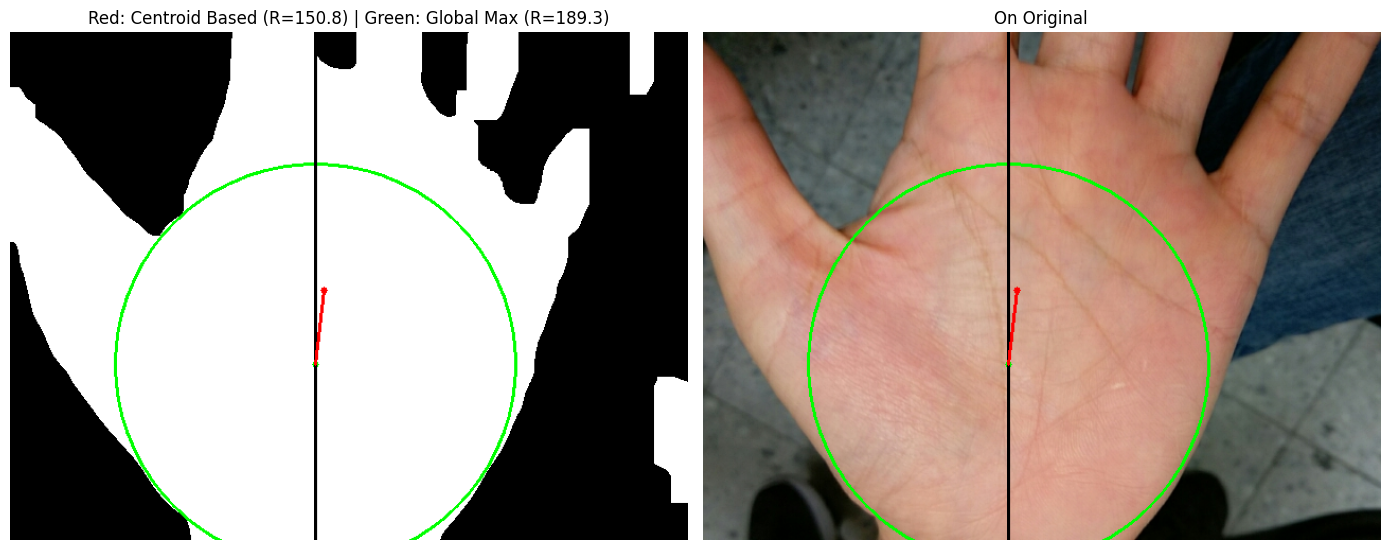

In [9]:
import copy

plt.figure(figsize=(14, 14))
plt.subplot(1, 2, 1)

# 直接对原二值图求距离变换
dist_transform = cv2.distanceTransform(img_gaus_gray_binary_eroded_dilated, cv2.DIST_L2, 5)
# 找到距离变换图中的最大值及其坐标
_, max_val, _, max_loc = cv2.minMaxLoc(dist_transform)

# 求原图质心
M = cv2.moments(img_gaus_gray_binary, binaryImage=True)
cx = int(M["m10"] / M["m00"])
cy = int(M["m01"] / M["m00"])

# 获取原图质心处的半径
radius = dist_transform[cy, cx]

def vis(img):
    if len(img.shape) == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    else:
        img = copy.deepcopy(img)
    # cv2.circle(vis, (cx, cy), int(radius), (0, 0, 255), 2)
    cv2.circle(img, (cx, cy), 3, (0, 0, 255), -1)
    
    # 绘制全局最大内切圆 (绿色)
    cv2.circle(img, max_loc, int(max_val), (0, 255, 0), 2)
    cv2.circle(img, max_loc, 3, (0, 255, 0), -1)
    
    y, x = img.shape[:2]
    cv2.line(img, max_loc, (max_loc[0],0), (0,0,0), 2)
    cv2.line(img, max_loc, (max_loc[0],y), (0,0,0), 2)
    cv2.line(img, max_loc, (cx, cy), (0,0,255), 2)

    return img

plt.subplot(1, 2, 1)
img_gaus_gray_binary_eroded_dilated_vis = vis(img_gaus_gray_binary_eroded_dilated)
plt.imshow(cv2.cvtColor(img_gaus_gray_binary_eroded_dilated_vis, cv2.COLOR_BGR2RGB))
plt.title(f"Red: Centroid Based (R={radius:.1f}) | Green: Global Max (R={max_val:.1f})")
plt.axis('off')
    
plt.subplot(1, 2, 2)
img_vis = vis(img)
plt.imshow(cv2.cvtColor(img_vis, cv2.COLOR_BGR2RGB))
plt.title(f"On Original")
plt.axis('off')

plt.tight_layout()
plt.show()

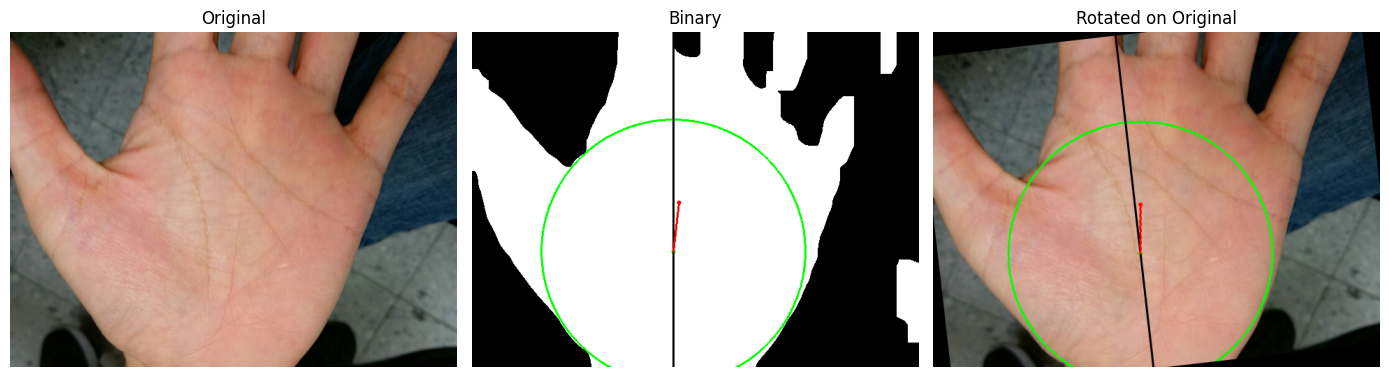

In [10]:
import math

def signed_angle_to_vertical(p1, p2, degrees=True):
    x1, y1 = p1
    x2, y2 = p2

    dx = x2 - x1
    dy = y2 - y1

    if dx == 0 and dy == 0:
        raise ValueError("两点重合，无法确定直线")

    # 以竖直向上为 0°，向右偏为正，向左偏为负
    angle = math.atan2(dx, dy)

    return math.degrees(angle) if degrees else angle



# 获取图像的高度和宽度
rows, cols = img.shape[:2]

# 设置旋转中心、旋转角度和缩放因子
center = (cols / 2, rows / 2)
angle = -signed_angle_to_vertical((cx, cy), max_loc)
scale = 1.0

# 生成旋转矩阵
M = cv2.getRotationMatrix2D(center, angle, scale)

plt.figure(figsize=(14, 14))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"Original")
plt.axis('off')

plt.subplot(1, 3, 2)
# 应用旋转矩阵
# img_gaus_gray_binary_eroded_dilated_vis_rotated = cv2.warpAffine(img_gaus_gray_binary_eroded_dilated_vis, M, (cols, rows))
plt.imshow(cv2.cvtColor(img_gaus_gray_binary_eroded_dilated_vis, cv2.COLOR_BGR2RGB))
plt.title(f"Binary")
plt.axis('off')

plt.subplot(1, 3, 3)
# 应用旋转矩阵
img_vis_rotated = cv2.warpAffine(img_vis, M, (cols, rows))
plt.imshow(cv2.cvtColor(img_vis_rotated, cv2.COLOR_BGR2RGB))
plt.title(f"Rotated on Original")
plt.axis('off')

plt.tight_layout()
plt.show()